In [1]:
!pip install pandas numpy nltk scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 558.9 kB/s eta 0:00:03
   ----------- ---------------------------- 0.5/1.8 MB 558.9 kB/s eta 0:00:03
   ----------- ---------------------------- 0.5/1.8 MB 558.9 kB/s eta 0:00:03
   ----------------- ---------------------- 0.8/1.8 MB 459.5 kB/s eta 0:00:03
   ----------------- ---------------------- 0.8/1.8 MB 459.5 kB/s eta 0:00:03
   ----------------- ---------------------- 0.8/1


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"

urllib.request.urlretrieve(URL, "data.zip")
with zipfile.ZipFile("data.zip") as z:
    z.extractall("data")

# find where the files ended up
for root, _, files in os.walk("data"):
    print(root, files)

data []
data\sentiment labelled sentences ['.DS_Store', 'amazon_cells_labelled.txt', 'imdb_labelled.txt', 'readme.txt', 'yelp_labelled.txt']
data\__MACOSX ['._sentiment labelled sentences']
data\__MACOSX\sentiment labelled sentences ['._.DS_Store', '._imdb_labelled.txt', '._readme.txt']


# load the dataset.

In [6]:
folder = "data/sentiment labelled sentences"

frames = []
for name in ["amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]:
    part = pd.read_csv(os.path.join(folder, name), sep="\t", header=None,
                       names=["text", "label"], quoting=3)
    part["source"] = name.split("_")[0]
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(3000, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [7]:
print(df.isnull().sum())
print(df["label"].value_counts())

text      0
label     0
source    0
dtype: int64
label
0    1500
1    1500
Name: count, dtype: int64


## Text preprocessing

In [8]:
def clean_text(text):
    text = str(text).lower()                  # 1. convert to lowercase
    text = re.sub(r"[^a-z\s]", " ", text)     # 2. remove punctuation, numbers, special characters
    text = re.sub(r"\s+", " ", text).strip()  # 3. remove extra whitespace
    return text

sample = "  Great phone!!!   Works 100% fine :)  "
print("Before:", repr(sample))
print("After: ", repr(clean_text(sample)))

Before: '  Great phone!!!   Works 100% fine :)  '
After:  'great phone works fine'


In [9]:
df["clean_text"] = df["text"].apply(clean_text)

In [10]:
pd.set_option("display.max_colwidth", 100)
df[["text", "clean_text"]].sample(8, random_state=42)

,text,clean_text
1801,Avoid at ALL costs!,avoid at all costs
1190,"Garbo, who showed right off the bat that her talents could carry over from the silent era (I wan...",garbo who showed right off the bat that her talents could carry over from the silent era i wante...
1817,You will leave the theater wanting to go out and dance under the stars.,you will leave the theater wanting to go out and dance under the stars
251,O my gosh the best phone I have ever had.,o my gosh the best phone i have ever had
2505,I would not recommend this place.,i would not recommend this place
1117,Then scene where they debated whether or not to sack the trumpeter (who falsely was accused for ...,then scene where they debated whether or not to sack the trumpeter who falsely was accused for t...
1411,Her role was played well.,her role was played well
2113,"Nice, spicy and tender.",nice spicy and tender


In [11]:
print("Empty sentences:", (df["clean_text"].str.len() == 0).sum())

Empty sentences: 2


In [12]:
df[df["clean_text"].str.len() == 0]

,text,label,source,clean_text
1125,10/10,1,imdb,
1788,10/10,1,imdb,


In [13]:
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print(df.shape)

(2998, 4)


## Explore the text data

In [21]:
print("POSITIVE EXAMPLES")
for t in df[df["label"] == 1]["text"].sample(5, random_state=1):
    print("+", t)

print("\n NEGATIVE EXAMPLES")
for t in df[df["label"] == 0]["text"].sample(5, random_state=1):
    print("-", t)

POSITIVE EXAMPLES
+ The file browser offers all the options that one needs.Handsfree is great.
+ My headset works just peachy-keen.
+ I will come back here every time I'm in Vegas.
+ Very wind-resistant.
+ Both Rickman and Stowe play their roles to the hilt in this tale of a childrens' book writer who-- maybe?-- has written a subversive tract.  

 NEGATIVE EXAMPLES
- Waste of 13 bucks.
- All I can do is whine on the Internet, so here it goes.The more I use the thing the less I like it.
- Not good for the money.
- Bluetooth does not work, phone locks up, screens just flash up and now it just makes calls randomly while in my pocket locked.
- Why are these sad little vegetables so overcooked?


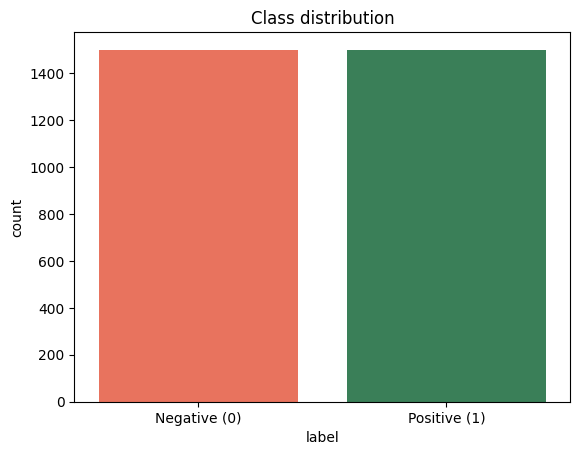

In [22]:
sns.countplot(data=df, x="label", hue="label", palette=["tomato", "seagreen"], legend=False)
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.title("Class distribution")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hesha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


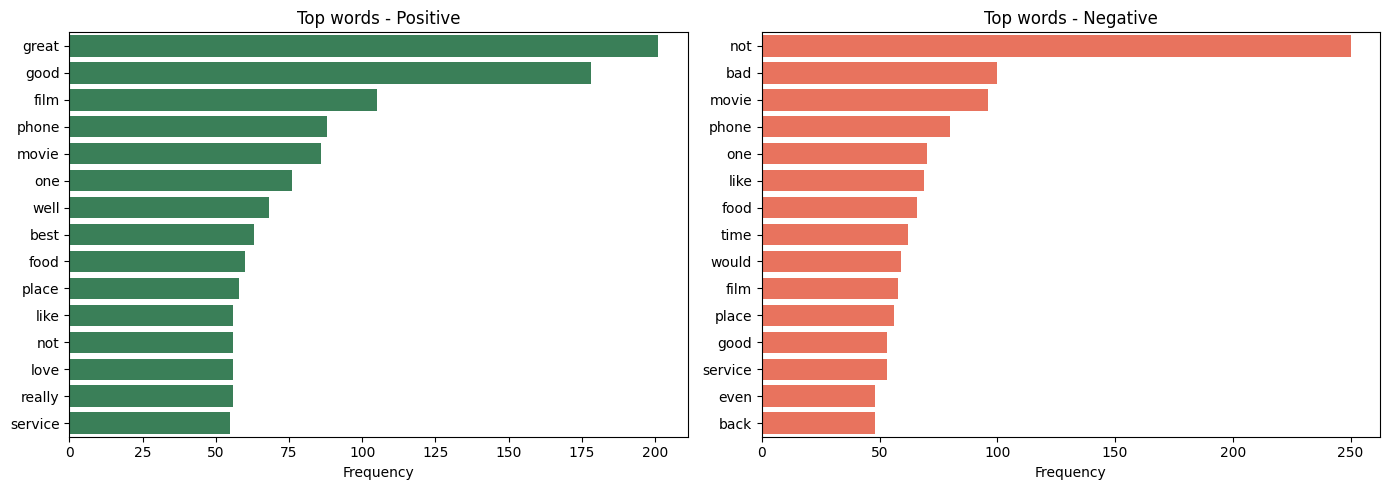

In [23]:
import nltk
from nltk.corpus import stopwords
from collections import Counter

nltk.download("stopwords")
stop = set(stopwords.words("english")) - {"not", "no", "nor", "never"}

def top_words(series, n=15):
    words = " ".join(series).split()
    words = [w for w in words if w not in stop and len(w) > 2]
    return Counter(words).most_common(n)

pos_top = top_words(df[df["label"] == 1]["clean_text"])
neg_top = top_words(df[df["label"] == 0]["clean_text"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, colour in zip(axes, [pos_top, neg_top],
                                   ["Top words - Positive", "Top words - Negative"],
                                   ["seagreen", "tomato"]):
    words, counts = zip(*data)
    sns.barplot(x=list(counts), y=list(words), ax=ax, color=colour)
    ax.set_title(title)
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### observations

###### Positive: great (~200) and good (~175) lead by a wide margin, followed by best, love, well and really. These are all clearly positive words.
###### Negative: not is the top word by far, at about 250 against only about 55 in the positive chart. bad comes next. would, even and back also rank high, probably from phrases like “would not recommend”, “not even” and “never going back”.

###### Positive reviews are dominated by sentiment words such as “great”, “good”, “best” and “love”, while negative reviews feature “not” and “bad”. Words like “movie”, “phone” and “food” appear frequently in both classes because they describe the subject matter, not the sentiment. The negation “not” is far more frequent in negative reviews, so removing it with the stop words would have lost useful information. The classes are balanced at 1,500 each.

# Split the dataset

In [24]:
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print(df.shape)

(2998, 4)


In [25]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]   # input: the cleaned sentences
y = df["label"]        # output: 0 or 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% for testing
    random_state=42,     # makes the split the same every time you run it
    stratify=y           # keeps the positive/negative ratio equal in both sets
)

print("Train size:", len(X_train))
print("Test size: ", len(X_test))
print("\nTrain class ratio:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class ratio:\n", y_test.value_counts(normalize=True).round(3))

Train size: 2398
Test size:  600

Train class ratio:
 label
0    0.5
1    0.5
Name: proportion, dtype: float64

Test class ratio:
 label
1    0.5
0    0.5
Name: proportion, dtype: float64


# Bag-of-Words (BOW)

In [26]:
from sklearn.feature_extraction.text import CountVectorizer

example = ["the food was great", "the food was not great"]
demo = CountVectorizer()
demo_matrix = demo.fit_transform(example)

print(pd.DataFrame(demo_matrix.toarray(), columns=demo.get_feature_names_out(), index=example))

                        food  great  not  the  was
the food was great         1      1    0    1    1
the food was not great     1      1    1    1    1


In [27]:
bow = CountVectorizer()

X_train_bow = bow.fit_transform(X_train)   # learn the vocabulary from TRAINING data, then convert it
X_test_bow = bow.transform(X_test)         # convert test data using that same vocabulary

print("Vocabulary size:", len(bow.vocabulary_))
print("Train matrix shape:", X_train_bow.shape)
print("Test matrix shape: ", X_test_bow.shape)

Vocabulary size: 4483
Train matrix shape: (2398, 4483)
Test matrix shape:  (600, 4483)


In [28]:
sparsity = 1 - X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1])
print(f"Sparsity: {sparsity:.2%} of the matrix is zeros")

Sparsity: 99.76% of the matrix is zeros


# Train ML models

In [29]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_bow, y_train)

print("Logistic Regression trained")

Logistic Regression trained


In [30]:
from sklearn.svm import LinearSVC

svm = LinearSVC(random_state=42)
svm.fit(X_train_bow, y_train)

print("SVM trained")

SVM trained


In [31]:
feature_names = np.array(bow.get_feature_names_out())
coefs = log_reg.coef_[0]

print("Most POSITIVE words:", list(feature_names[np.argsort(coefs)[-10:][::-1]]))
print("Most NEGATIVE words:", list(feature_names[np.argsort(coefs)[:10]]))

Most POSITIVE words: ['great', 'love', 'excellent', 'best', 'good', 'nice', 'awesome', 'loved', 'delicious', 'amazing']
Most NEGATIVE words: ['bad', 'poor', 'worst', 'not', 'terrible', 'awful', 'wasn', 'disappointment', 'didn', 'stupid']


# Evaluate the models

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {"Logistic Regression": log_reg, "Linear SVM": svm}
rows = []
preds = {}

for name, model in models.items():
    y_pred = model.predict(X_test_bow)    # predictions on unseen test data
    preds[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.7767,0.773,0.7833,0.7781
Linear SVM,0.7950,0.781,0.8200,0.8000


In [33]:
from sklearn.metrics import classification_report

for name, y_pred in preds.items():
    print("=" * 55)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.78      0.77      0.78       300
    Positive       0.77      0.78      0.78       300

    accuracy                           0.78       600
   macro avg       0.78      0.78      0.78       600
weighted avg       0.78      0.78      0.78       600

Linear SVM
              precision    recall  f1-score   support

    Negative       0.81      0.77      0.79       300
    Positive       0.78      0.82      0.80       300

    accuracy                           0.80       600
   macro avg       0.80      0.79      0.79       600
weighted avg       0.80      0.80      0.79       600



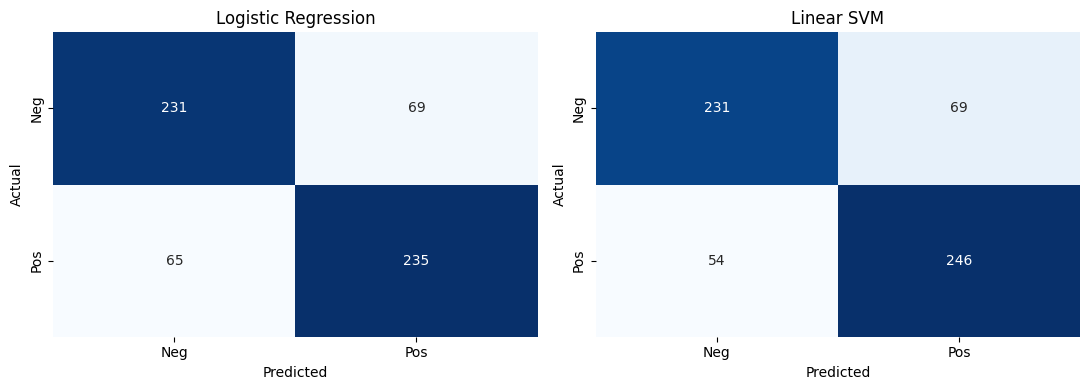

In [35]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [36]:
errors = X_test[preds["Logistic Regression"] != y_test]
print("Logistic Regression got", len(errors), "wrong. Examples:\n")
for text, true in zip(errors.head(8), y_test[errors.head(8).index]):
    print(f"[actual: {'Pos' if true == 1 else 'Neg'}] {text}")

Logistic Regression got 134 wrong. Examples:

[actual: Pos] however after finally watching this film i realized that not only had i had a closed mind to the brilliance it depicts i also found myself watching it over and over again
[actual: Pos] the goat taco didn t skimp on the meat and wow what flavor
[actual: Pos] she is as lovely as usual this cutie
[actual: Neg] the burger i got the gold standard a burger and was kind of disappointed
[actual: Pos] omelets are to die for
[actual: Pos] someone shouldve invented this sooner
[actual: Pos] not a weekly haunt but definitely a place to come back to every once in a while
[actual: Pos] the story is also both funny and poignant at times


# Test the model with new sentences

In [37]:
def predict_sentiment(sentence, model):
    cleaned = clean_text(sentence)         # same cleaning as training
    vec = bow.transform([cleaned])         # same vocabulary as training
    label = model.predict(vec)[0]
    return "Positive" if label == 1 else "Negative"

new_sentences = [
    "I absolutely loved this movie, the acting was brilliant!",
    "The food was cold and the service was terrible.",
    "This phone has an amazing battery life.",
    "I would not recommend this product to anyone.",
    "It was okay, nothing special.",
    "The room wasn't clean at all.",
]

for s in new_sentences:
    print(s)
    print("   Logistic Regression ->", predict_sentiment(s, log_reg))
    print("   SVM                 ->", predict_sentiment(s, svm))
    print()

I absolutely loved this movie, the acting was brilliant!
   Logistic Regression -> Positive
   SVM                 -> Positive

The food was cold and the service was terrible.
   Logistic Regression -> Negative
   SVM                 -> Negative

This phone has an amazing battery life.
   Logistic Regression -> Positive
   SVM                 -> Positive

I would not recommend this product to anyone.
   Logistic Regression -> Negative
   SVM                 -> Negative

It was okay, nothing special.
   Logistic Regression -> Negative
   SVM                 -> Negative

The room wasn't clean at all.
   Logistic Regression -> Negative
   SVM                 -> Negative



In [38]:
my_sentences = [
    "My favourite hobby is going shopping with my friends on the weekend.",
]
for s in my_sentences:
    print(s, "->", predict_sentiment(s, svm))

My favourite hobby is going shopping with my friends on the weekend. -> Positive


In [39]:
tricky = [
    "The movie was not bad at all.",       # negation flips meaning
    "Oh great, another broken phone.",     # sarcasm
    "The food was good but the service was awful.",  # mixed sentiment
]
for s in tricky:
    print(s)
    print("   Logistic Regression ->", predict_sentiment(s, log_reg))
    print("   SVM                 ->", predict_sentiment(s, svm))
    print()

The movie was not bad at all.
   Logistic Regression -> Negative
   SVM                 -> Negative

Oh great, another broken phone.
   Logistic Regression -> Positive
   SVM                 -> Positive

The food was good but the service was awful.
   Logistic Regression -> Negative
   SVM                 -> Negative



# conclusion

##### In this lab I built a sentiment classifier on the UCI Sentiment Labelled Sentences dataset (3,000 sentences from Amazon, IMDB and Yelp). After cleaning the text (lowercasing, removing punctuation and extra whitespace) and removing two empty rows, I split the data 80/20 with stratification and converted the sentences into a Bag-of-Words matrix with a vocabulary of 4,483 words. I trained Logistic Regression and a Linear SVM. On the test set the SVM performed slightly better (accuracy about 0.795, F1 about 0.800) than Logistic Regression (accuracy about 0.777, F1 about 0.778).

##### The models learned sensible sentiment words (e.g. “great”, “love”, “excellent” vs “bad”, “poor”, “worst”), and they classified clear new sentences correctly. However, Bag-of-Words ignores word order, so it struggles with negation, idioms and mixed sentiment. My preprocessing also split contractions such as “didn’t” into “didn” and “t”, so the model learned fragments like “didn” and “wasn” as negative signals. A binary classifier also cannot recognise neutral text.

##### Possible improvements include expanding contractions before cleaning, using TF-IDF or n-grams (so that “not good” is captured as one feature), tuning hyperparameters with cross-validation, and using pretrained language models, which can handle context.